In [10]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50, Xception
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: []


In [12]:
BASE_PATH = "/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data"

TRAIN_PATH = os.path.join(BASE_PATH, "Train")
VAL_PATH = os.path.join(BASE_PATH, "Val")
TEST_PATH = os.path.join(BASE_PATH, "Test")

CLASSES = ["COVID-19", "Non-COVID", "Normal"]

print("Base path:", BASE_PATH)
print("Train path:", TRAIN_PATH)
print("Validation path:", VAL_PATH)
print("Test path:", TEST_PATH)

print("\nClasses:")
for cls in CLASSES:
    print("-", cls)

Base path: /kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data
Train path: /kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Train
Validation path: /kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Val
Test path: /kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test

Classes:
- COVID-19
- Non-COVID
- Normal


In [13]:
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def count_images(folder):
    results = {}

    for cls in CLASSES:
        image_folder = os.path.join(folder, cls, "images")

        if os.path.exists(image_folder):
            count = sum(
                1 for f in os.listdir(image_folder)
                if f.lower().endswith(valid_extensions)
            )
        else:
            count = 0

        results[cls] = count

    return results


print("TRAIN:")
print(count_images(TRAIN_PATH))

print("\nVALIDATION:")
print(count_images(VAL_PATH))

print("\nTEST:")
print(count_images(TEST_PATH))

TRAIN:
{'COVID-19': 1864, 'Non-COVID': 932, 'Normal': 932}

VALIDATION:
{'COVID-19': 466, 'Non-COVID': 233, 'Normal': 233}

TEST:
{'COVID-19': 583, 'Non-COVID': 292, 'Normal': 291}


In [15]:
random.seed(42)

# Total = 100 images
TRAIN_COUNTS = {
    "COVID-19": 27,
    "Non-COVID": 27,
    "Normal": 26
}

VAL_COUNTS = {
    "COVID-19": 3,
    "Non-COVID": 3,
    "Normal": 4
}

TEST_COUNTS = {
    "COVID-19": 4,
    "Non-COVID": 3,
    "Normal": 3
}


def get_images(folder, class_name, number):
    image_folder = os.path.join(folder, class_name, "images")

    image_files = [
        os.path.join(image_folder, f)
        for f in os.listdir(image_folder)
        if f.lower().endswith(valid_extensions)
    ]

    random.shuffle(image_files)

    return image_files[:number]


def create_dataframe(folder, counts, split_name):
    data = []

    for cls in CLASSES:
        files = get_images(folder, cls, counts[cls])

        for file in files:
            data.append({
                "filepath": file,
                "class": cls,
                "split": split_name
            })

    return pd.DataFrame(data)


train_df = create_dataframe(
    TRAIN_PATH,
    TRAIN_COUNTS,
    "Train"
)

val_df = create_dataframe(
    VAL_PATH,
    VAL_COUNTS,
    "Val"
)

test_df = create_dataframe(
    TEST_PATH,
    TEST_COUNTS,
    "Test"
)

df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("Total images:", len(df))
print("\nImages per split:")
print(df["split"].value_counts())

print("\nImages per class:")
print(df["class"].value_counts())

print("\nDetailed distribution:")
print(
    df.groupby(["split", "class"])
      .size()
      .reset_index(name="count")
)

Total images: 100

Images per split:
split
Train    80
Val      10
Test     10
Name: count, dtype: int64

Images per class:
class
COVID-19     34
Non-COVID    33
Normal       33
Name: count, dtype: int64

Detailed distribution:
   split      class  count
0   Test   COVID-19      4
1   Test  Non-COVID      3
2   Test     Normal      3
3  Train   COVID-19     27
4  Train  Non-COVID     27
5  Train     Normal     26
6    Val   COVID-19      3
7    Val  Non-COVID      3
8    Val     Normal      4


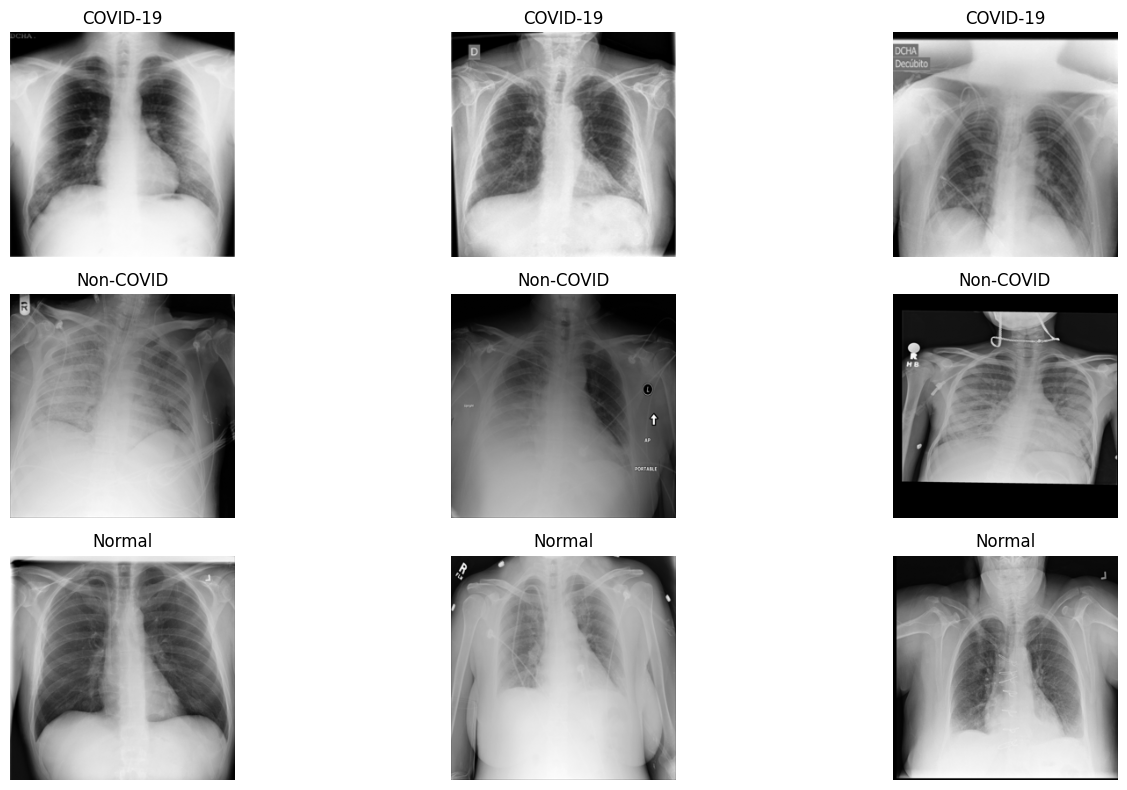

In [16]:
plt.figure(figsize=(15, 8))

sample_df = df.groupby("class", group_keys=False).head(3)

for i, (_, row) in enumerate(sample_df.iterrows()):
    image = Image.open(row["filepath"])

    plt.subplot(3, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(row["class"])
    plt.axis("off")

plt.tight_layout()
plt.show()

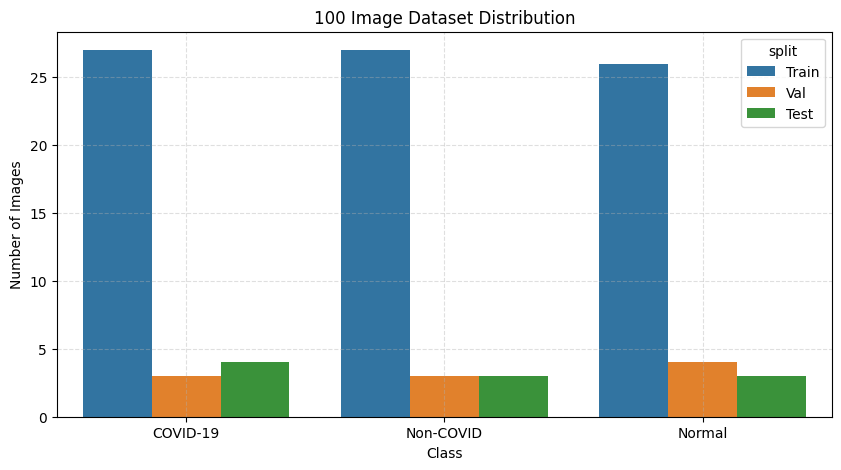

In [17]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="class",
    hue="split"
)

plt.title("100 Image Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.show()

In [18]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 4
NUM_CLASSES = 3

label_map = {
    "COVID-19": 0,
    "Non-COVID": 1,
    "Normal": 2
}

train_df["label"] = train_df["class"].map(label_map)
val_df["label"] = val_df["class"].map(label_map)
test_df["label"] = test_df["class"].map(label_map)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (128, 128)
Batch size: 4
Number of classes: 3


In [32]:
def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


def make_dataset(dataframe, preprocess_function, training=False):

    paths = dataframe["filepath"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    def preprocess(image, label):
        image = preprocess_function(image)
        return image, label

    dataset = dataset.map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [33]:
train_resnet = make_dataset(
    train_df,
    resnet_preprocess,
    training=True
)

val_resnet = make_dataset(
    val_df,
    resnet_preprocess
)

test_resnet = make_dataset(
    test_df,
    resnet_preprocess
)

print("ResNet datasets created successfully.")

ResNet datasets created successfully.


In [38]:
print("Creating ResNet50 model...")

resnet_base = ResNet50(
    weights=None,              # IMPORTANT: no internet download
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze base model
resnet_base.trainable = False

resnet_input = tf.keras.Input(
    shape=(128, 128, 3)
)

x = resnet_base(
    resnet_input,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

resnet_output = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

resnet_model = Model(
    resnet_input,
    resnet_output
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

Creating ResNet50 model...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [39]:
print("Creating ResNet50 model...")

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

NUM_CLASSES = 3
IMG_SIZE = (128, 128)

resnet_base = ResNet50(
    weights=None,              # No internet/download required
    include_top=False,
    input_shape=(128, 128, 3)
)

# Train from scratch because weights=None
resnet_base.trainable = True

resnet_input = tf.keras.Input(
    shape=(128, 128, 3)
)

x = resnet_base(resnet_input)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

resnet_output = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

resnet_model = Model(
    inputs=resnet_input,
    outputs=resnet_output
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 model created successfully!")
resnet_model.summary()

Creating ResNet50 model...
ResNet50 model created successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 23,797,251 (90.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [40]:
print("Starting ResNet50 training...")

history_resnet = resnet_model.fit(
    train_resnet,
    validation_data=val_resnet,
    epochs=3,
    verbose=1
)

print("ResNet50 training completed!")

Starting ResNet50 training...
Epoch 1/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 569ms/step - accuracy: 0.3250 - loss: 1.8781 - val_accuracy: 0.7000 - val_loss: 1.0225
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 488ms/step - accuracy: 0.3875 - loss: 1.5254 - val_accuracy: 0.3000 - val_loss: 1.1078
Epoch 3/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 481ms/step - accuracy: 0.3750 - loss: 1.3990 - val_accuracy: 0.3000 - val_loss: 1.1972
ResNet50 training completed!


In [41]:
print("Evaluating ResNet50...")

resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    test_resnet,
    verbose=1
)

print(f"\nResNet50 Test Loss: {resnet_test_loss:.4f}")
print(f"ResNet50 Test Accuracy: {resnet_test_accuracy:.4f}")

Evaluating ResNet50...
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.4000 - loss: 1.1204

ResNet50 Test Loss: 1.1204
ResNet50 Test Accuracy: 0.4000


ResNet50 Classification Report:

              precision    recall  f1-score   support

    COVID-19       0.40      1.00      0.57         4
   Non-COVID       0.00      0.00      0.00         3
      Normal       0.00      0.00      0.00         3

    accuracy                           0.40        10
   macro avg       0.13      0.33      0.19        10
weighted avg       0.16      0.40      0.23        10



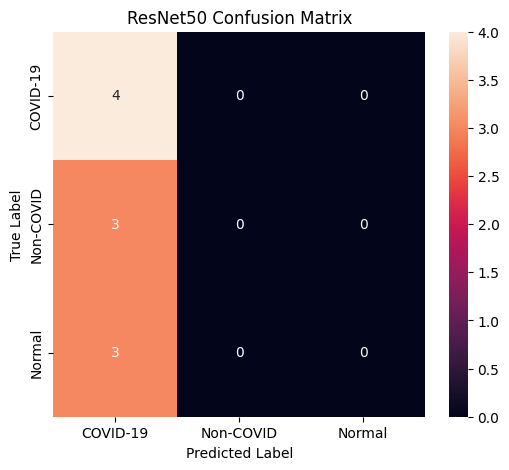

In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# True labels
y_true_resnet = []
for _, labels in test_resnet:
    y_true_resnet.extend(labels.numpy())

y_true_resnet = np.array(y_true_resnet)

# Predictions
y_prob_resnet = resnet_model.predict(test_resnet, verbose=0)
y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

print("ResNet50 Classification Report:\n")
print(
    classification_report(
        y_true_resnet,
        y_pred_resnet,
        target_names=["COVID-19", "Non-COVID", "Normal"],
        zero_division=0
    )
)

# Confusion matrix
cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    xticklabels=["COVID-19", "Non-COVID", "Normal"],
    yticklabels=["COVID-19", "Non-COVID", "Normal"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet50 Confusion Matrix")
plt.show()

In [43]:
print("Creating Xception model...")

from tensorflow.keras.applications import Xception

xception_base = Xception(
    weights=None,
    include_top=False,
    input_shape=(128, 128, 3)
)

xception_base.trainable = True

xception_input = tf.keras.Input(
    shape=(128, 128, 3)
)

x = xception_base(xception_input)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

xception_output = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

xception_model = Model(
    inputs=xception_input,
    outputs=xception_output
)

xception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Xception model created successfully!")
xception_model.summary()

Creating Xception model...
Xception model created successfully!


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 4, 4, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,124,139 (80.58 MB)

 Trainable params: 21,069,611 (80.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [46]:
# Create Xception datasets

train_xception = create_dataset(
    train_df,
    preprocess_fn=xception_preprocess,
    training=True
)

val_xception = create_dataset(
    val_df,
    preprocess_fn=xception_preprocess,
    training=False
)

test_xception = create_dataset(
    test_df,
    preprocess_fn=xception_preprocess,
    training=False
)

print("Xception datasets created successfully!")

NameError: name 'create_dataset' is not defined

In [44]:
print("Starting Xception training...")

history_xception = xception_model.fit(
    train_xception,
    validation_data=val_xception,
    epochs=3,
    verbose=1
)

print("Xception training completed!")

Starting Xception training...


NameError: name 'train_xception' is not defined

In [47]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input

IMG_SIZE = (128, 128)
BATCH_SIZE = 4
NUM_CLASSES = 3

def create_xception_dataset(df, training=False):

    paths = df["filepath"].values
    labels = df["label"].values

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32)

        image = preprocess_input(image)

        return image, label

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_xception = create_xception_dataset(
    train_df,
    training=True
)

val_xception = create_xception_dataset(
    val_df,
    training=False
)

test_xception = create_xception_dataset(
    test_df,
    training=False
)

print("Xception datasets ready!")

Xception datasets ready!


In [48]:
print("Creating Xception model...")

xception_base = Xception(
    weights=None,
    include_top=False,
    input_shape=(128, 128, 3)
)

# Train Xception from scratch
xception_base.trainable = True

inputs = tf.keras.Input(
    shape=(128, 128, 3)
)

x = xception_base(inputs)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

xception_model = Model(
    inputs=inputs,
    outputs=outputs
)

xception_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Xception model ready!")

xception_model.summary()

Creating Xception model...
Xception model ready!


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 4, 4, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,124,139 (80.58 MB)

 Trainable params: 21,069,611 (80.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [49]:
print("Starting Xception training...")

history_xception = xception_model.fit(
    train_xception,
    validation_data=val_xception,
    epochs=3,
    verbose=1
)

print("Xception training completed!")

Starting Xception training...
Epoch 1/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 563ms/step - accuracy: 0.5000 - loss: 1.0303 - val_accuracy: 0.3000 - val_loss: 1.0990
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 512ms/step - accuracy: 0.6125 - loss: 0.8841 - val_accuracy: 0.3000 - val_loss: 1.0993
Epoch 3/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 505ms/step - accuracy: 0.8000 - loss: 0.6610 - val_accuracy: 0.3000 - val_loss: 1.0996
Xception training completed!


In [50]:
print("Evaluating Xception...")

xception_test_loss, xception_test_accuracy = xception_model.evaluate(
    test_xception,
    verbose=1
)

print(f"\nXception Test Loss: {xception_test_loss:.4f}")
print(f"Xception Test Accuracy: {xception_test_accuracy:.4f}")

Evaluating Xception...
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.4000 - loss: 1.0976

Xception Test Loss: 1.0976
Xception Test Accuracy: 0.4000


Xception Classification Report:

              precision    recall  f1-score   support

    COVID-19       0.40      1.00      0.57         4
   Non-COVID       0.00      0.00      0.00         3
      Normal       0.00      0.00      0.00         3

    accuracy                           0.40        10
   macro avg       0.13      0.33      0.19        10
weighted avg       0.16      0.40      0.23        10



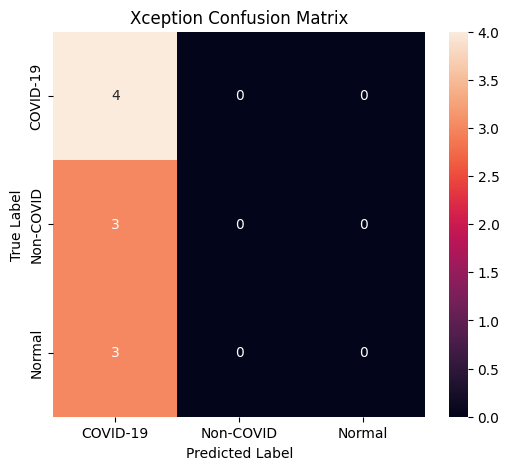

In [51]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# True labels
y_true_xception = []

for _, labels in test_xception:
    y_true_xception.extend(labels.numpy())

y_true_xception = np.array(y_true_xception)

# Predictions
y_prob_xception = xception_model.predict(
    test_xception,
    verbose=0
)

y_pred_xception = np.argmax(
    y_prob_xception,
    axis=1
)

print("Xception Classification Report:\n")

print(
    classification_report(
        y_true_xception,
        y_pred_xception,
        target_names=[
            "COVID-19",
            "Non-COVID",
            "Normal"
        ],
        zero_division=0
    )
)

# Confusion Matrix
cm_xception = confusion_matrix(
    y_true_xception,
    y_pred_xception
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xception,
    annot=True,
    fmt="d",
    xticklabels=[
        "COVID-19",
        "Non-COVID",
        "Normal"
    ],
    yticklabels=[
        "COVID-19",
        "Non-COVID",
        "Normal"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Xception Confusion Matrix")
plt.show()